<a href="https://colab.research.google.com/github/inamoorata/PCD_Assignment02/blob/main/PCD_Assigment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

Membaca RGB dan menampilkan citra dengan matplotlib

In [17]:
def to_uint8(img):
  return np.clip(img, 0, 255).astype(np.uint8)

def load(path):
  img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
  if img.ndim == 3:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  return img

def show(images, titles, figsize=(12, 4)):
  fig, ax = plt.subplots(1, len(images), figsize=figsize)
  if len(images) == 1:
    ax = [ax]
  for a, im, t in zip(ax, images, titles):
    a.imshow(im, cmap='gray' if im.ndim == 2 else None, vmin=0, vmax=255)
    a.set_title(t)
    a.axis('off')
  plt.tight_layout
  plt.show()

Mempertajam citra blur dengan Gaussian dan Laplacian Filter

In [18]:
def enhance_blur(img, gaussian_ksize=3, k=1.6):
  denoised = cv2.GaussianBlur(img, (gaussian_ksize, gaussian_ksize), 0)
  lap = cv2.Laplacian(denoised, cv2.CV_64F, ksize=3)
  return to_uint8(denoised.astype(np.float64) - k * lap)

Mencerahkan dark image dengan log transform

In [19]:
def log_transform(img):
  img_f = img.astype(np.float32)
  c = 255.0 / np.log(1 + np.max(img_f) + 1e-6)
  return to_uint8(c * np.log(1 + img_f))

Meredupkan citra yang teralu terang dengan inverse log transform

In [20]:
def inverse_log(img):
  img_f = img.astype(np.float32)
  c = 255.0 / np.log(1 + np.max(img_f) + 1e-6)
  result = np.exp(img_f / c) - 1
  return to_uint8(result / (np.max(result) + 1e-6) * 255.0)

Meningkatkan citra low contrast dengan contrast stretching

In [21]:
def contrast_stretching(img, low_pct=1, high_pct=99):
  img_f = img.astype(np.float32)
  r_min, r_max = np.percentile(img_f, low_pct), np.percentile(img_f, high_pct)
  return to_uint8((img_f - r_min) / (r_max - r_min + 1e-6) * 255.0)

Mengurangi noise pada citra dengan mean, gaussian, dan median filter

In [22]:
def mean(img, ksize=5):
  return cv2.blur(img, (ksize, ksize))

def gaussian(img, ksize=5, sigma=1.5):
  return cv2.GaussianBlur(img, (ksize, ksize), sigma)

def median(img, ksize=5):
  return cv2.medianBlur(img, ksize)

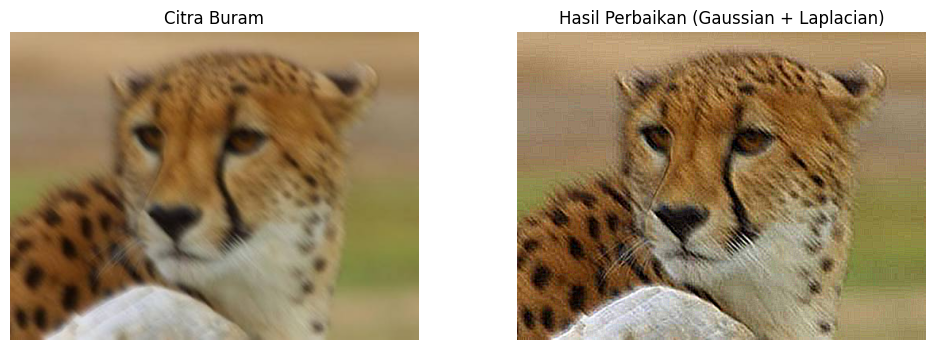

In [23]:
blur_img = load("blur3.jpg")
enhanced1 = enhance_blur(blur_img)
show(
    [blur_img, enhanced1],
    ["Citra Buram", "Hasil Perbaikan (Gaussian + Laplacian)"],
)

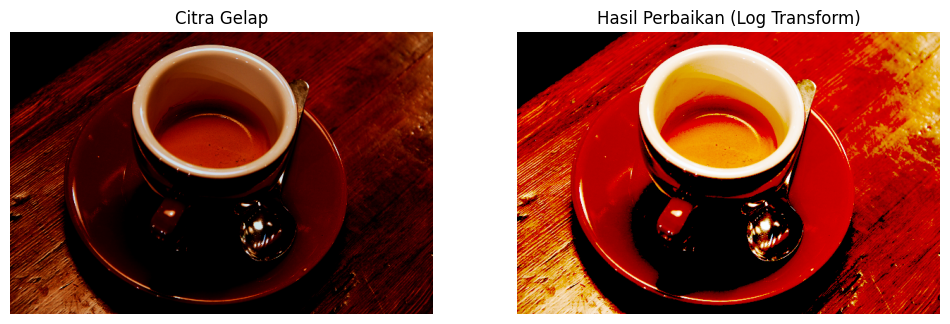

In [24]:
dark_img = load("dark3.png")
enhanced2 = log_transform(dark_img)
show([dark_img, enhanced2], ["Citra Gelap", "Hasil Perbaikan (Log Transform)"])

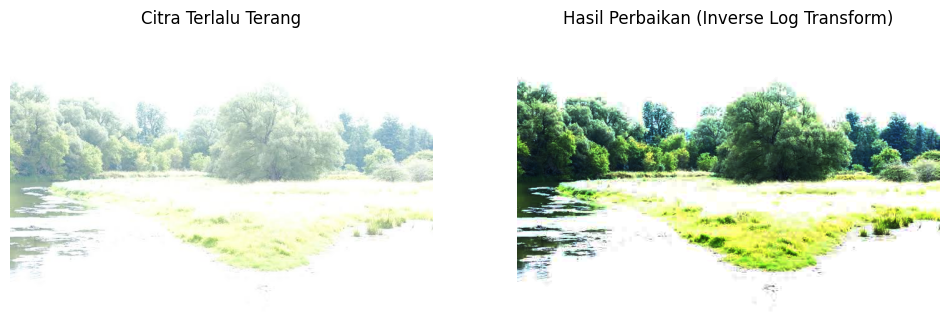

In [25]:
bright_img = load("bright.jpg")
enhanced3 = inverse_log(bright_img)
show(
    [bright_img, enhanced3],
    ["Citra Terlalu Terang", "Hasil Perbaikan (Inverse Log Transform)"],
    )

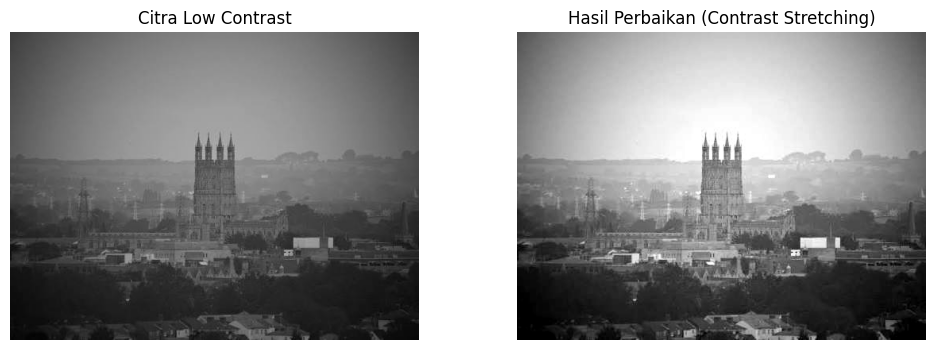

In [26]:
lowc_img = load("lowcont.jpg")
enhanced4 = contrast_stretching(lowc_img)
show(
    [lowc_img, enhanced4],
    ["Citra Low Contrast", "Hasil Perbaikan (Contrast Stretching)"],
)

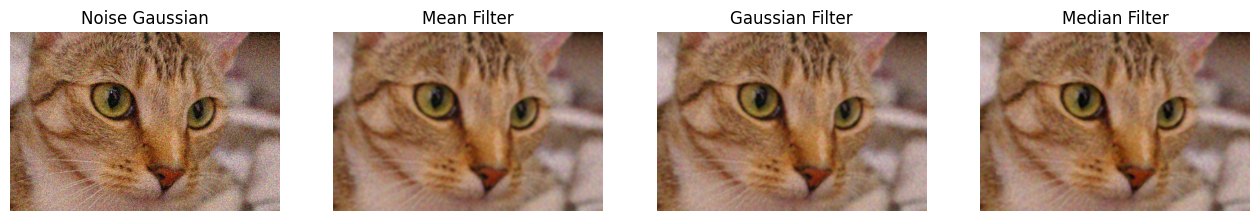

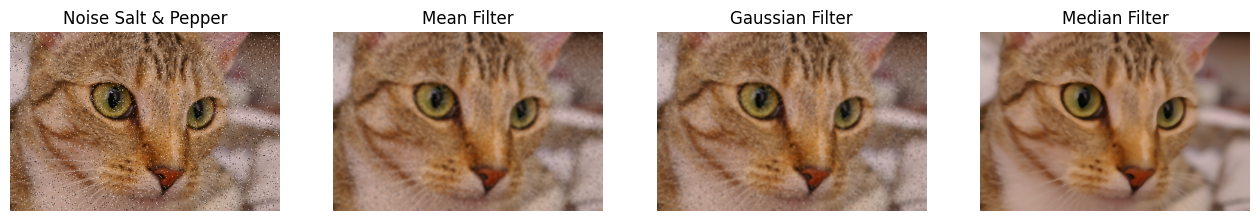

In [27]:
noise_g = load("noise_gauss.png")
noise_sp = load("noise_sp.png")

show(
    [
        noise_g,
        mean(noise_g),
        gaussian(noise_g),
        median(noise_g),
    ],
    ["Noise Gaussian", "Mean Filter", "Gaussian Filter", "Median Filter"],
    figsize=(16, 4),
)

show(
    [
        noise_sp,
        mean(noise_sp),
        gaussian(noise_sp),
        median(noise_sp),
    ],
    ["Noise Salt & Pepper", "Mean Filter", "Gaussian Filter", "Median Filter"],
    figsize=(16, 4),
)